<a href="https://colab.research.google.com/github/ansumanbebarta/abc/blob/master/STUDENT_ID_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [87]:
!pip install datasets

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset

In [88]:
# Part 1 - Dataset processing
dataset = load_dataset("gvlassis/california_housing")

train_df = dataset['train'].to_pandas()
val_df = dataset['validation'].to_pandas()
test_df = dataset['test'].to_pandas()

In [89]:
# Part 2 - Build the feature matrix
X = train_df.iloc[:, :8].to_numpy()
X = np.insert(X, 0, 1, axis=1)

In [90]:
# Part 3 - Build the output matrix
y = train_df.iloc[:, 8].to_numpy().reshape(-1, 1)

In [91]:
# Part 4 - Performing linear regression
lambda_ = 1.0
w = np.linalg.inv((X.T @ X) + lambda_ * np.eye(9)) @ (X.T @ y)

In [92]:
# Part 5 - Calculate test loss
X_test = test_df.iloc[:, :8].to_numpy()
X_test = np.insert(X_test, 0, 1, axis=1)
y_test = test_df.iloc[:, 8].to_numpy().reshape(-1, 1)
y_test_hat = X_test @ w

test_loss = np.sum((y_test - y_test_hat) ** 2)
print(test_loss)


731.2029561668917


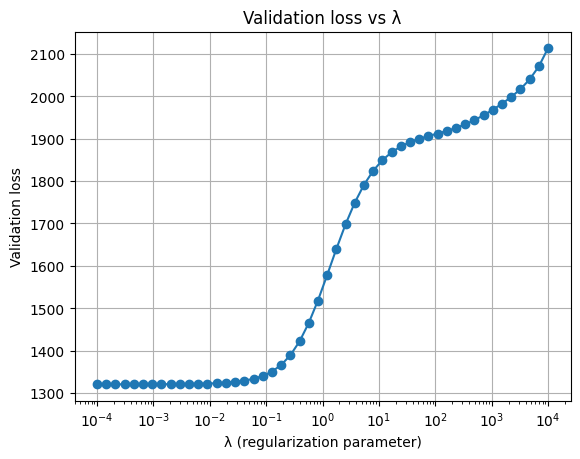

Best Lambda: 0.0001
Test Loss at Best Lambda: 683.1233277514135


In [95]:
# Part 6 - Hyperparameter tuning
lambdas = np.logspace(-4, 4, 50)
X_val = val_df.iloc[:, :8].to_numpy()
X_val = np.insert(X_val, 0, 1, axis=1)
y_val = val_df.iloc[:, 8].to_numpy().reshape(-1, 1)

val_losses = []
for lambda_ in lambdas:
  w = np.linalg.inv((X.T @ X) + lambda_ * np.eye(9)) @ (X.T @ y)
  y_val_hat = X_val @ w
  val_losses.append(np.sum((y_val - y_val_hat) ** 2))

best_index = np.argmin(val_losses)
best_lambda = lambdas[best_index]

w_best = np.linalg.inv((X.T @ X) + best_lambda * np.eye(9)) @ (X.T @ y)
test_loss_best = np.sum((y_test - X_test @ w_best) ** 2)

plt.plot(lambdas, val_losses, marker='o')

plt.grid(True)
plt.xscale('log')
plt.xlabel("λ (regularization parameter)")
plt.ylabel("Validation loss")
plt.title("Validation loss vs λ")
plt.show()

print("Best Lambda:", best_lambda)
print("Test Loss at Best Lambda:", test_loss_best)